# 01 — Exploratory Data Analysis (EDA)

**Project:** A Two-Stage Funnel Recommendation Architecture  
**Author:** Hüseyin Sefa Akçay (26040201005)  
**Dataset:** MovieLens 1M

---
This notebook explores the MovieLens 1M dataset to understand:
- Rating distribution and sparsity
- User activity patterns
- Item popularity (long-tail effect)
- Genre distribution
- Temporal patterns

These findings directly motivate the design choices in the funnel architecture.

In [39]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
from pathlib import Path
from IPython.display import display

from src.data.loader import MovieLensLoader
from src.utils.helpers import set_seed

set_seed(42)
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120
print('Libraries loaded ✓')

Libraries loaded ✓


## 1. Load Dataset

In [40]:
loader = MovieLensLoader(data_path='../data/raw/ml-1m')
ratings, movies, users = loader.load_all()
loader.summary()

  MovieLens 1M — Dataset Summary
  Users  :    6,040
  Items  :    3,706
  Ratings: 1,000,209
  Sparsity: 95.53%


In [41]:
print('--- Ratings sample ---')
display(ratings.head())
print('\n--- Movies sample ---')
display(movies.head())
print('\n--- Users sample ---')
display(users.head())

--- Ratings sample ---


,user_id,item_id,rating,timestamp,user_idx,item_idx
0,1,1193,5,978300760,0,1104
1,1,661,3,978302109,0,639
2,1,914,3,978301968,0,853
3,1,3408,4,978300275,0,3177
4,1,2355,5,978824291,0,2162



--- Movies sample ---


,item_id,title,genres,genre_list
0,1,Toy Story (1995),Animation|Children's|Comedy,"[Animation, Children's, Comedy]"
1,2,Jumanji (1995),Adventure|Children's|Fantasy,"[Adventure, Children's, Fantasy]"
2,3,Grumpier Old Men (1995),Comedy|Romance,"[Comedy, Romance]"
3,4,Waiting to Exhale (1995),Comedy|Drama,"[Comedy, Drama]"
4,5,Father of the Bride Part II (1995),Comedy,[Comedy]



--- Users sample ---


,user_id,gender,age,occupation,zip
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


## 2. Rating Distribution

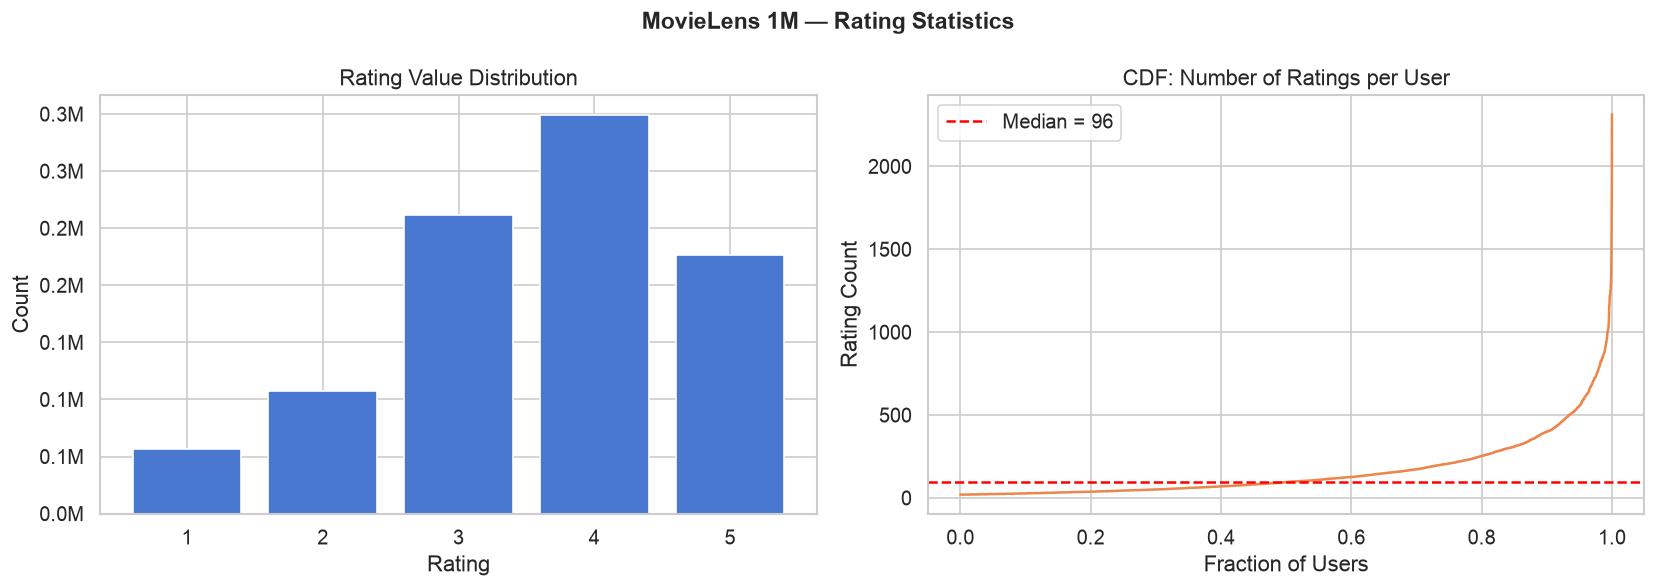

Mean rating  : 3.582
Std  rating  : 1.117
Median ratings/user : 96
Max ratings/user    : 2314


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Rating value histogram
rating_counts = ratings['rating'].value_counts().sort_index()
axes[0].bar(rating_counts.index, rating_counts.values, color=sns.color_palette('muted')[0], edgecolor='white')
axes[0].set_title('Rating Value Distribution')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Count')
axes[0].yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))

# Ratings per user (CDF)
user_counts = ratings.groupby('user_idx')['item_idx'].count().sort_values()
axes[1].plot(np.arange(len(user_counts)) / len(user_counts), user_counts.values, color=sns.color_palette('muted')[1])
axes[1].set_title('CDF: Number of Ratings per User')
axes[1].set_xlabel('Fraction of Users')
axes[1].set_ylabel('Rating Count')
axes[1].axhline(user_counts.median(), color='red', linestyle='--', label=f'Median = {user_counts.median():.0f}')
axes[1].legend()

plt.suptitle('MovieLens 1M — Rating Statistics', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/intermediate_report/fig_rating_dist.png', bbox_inches='tight')
plt.show()

print(f'Mean rating  : {ratings["rating"].mean():.3f}')
print(f'Std  rating  : {ratings["rating"].std():.3f}')
print(f'Median ratings/user : {user_counts.median():.0f}')
print(f'Max ratings/user    : {user_counts.max()}')

## 3. Item Popularity — Long-Tail Effect

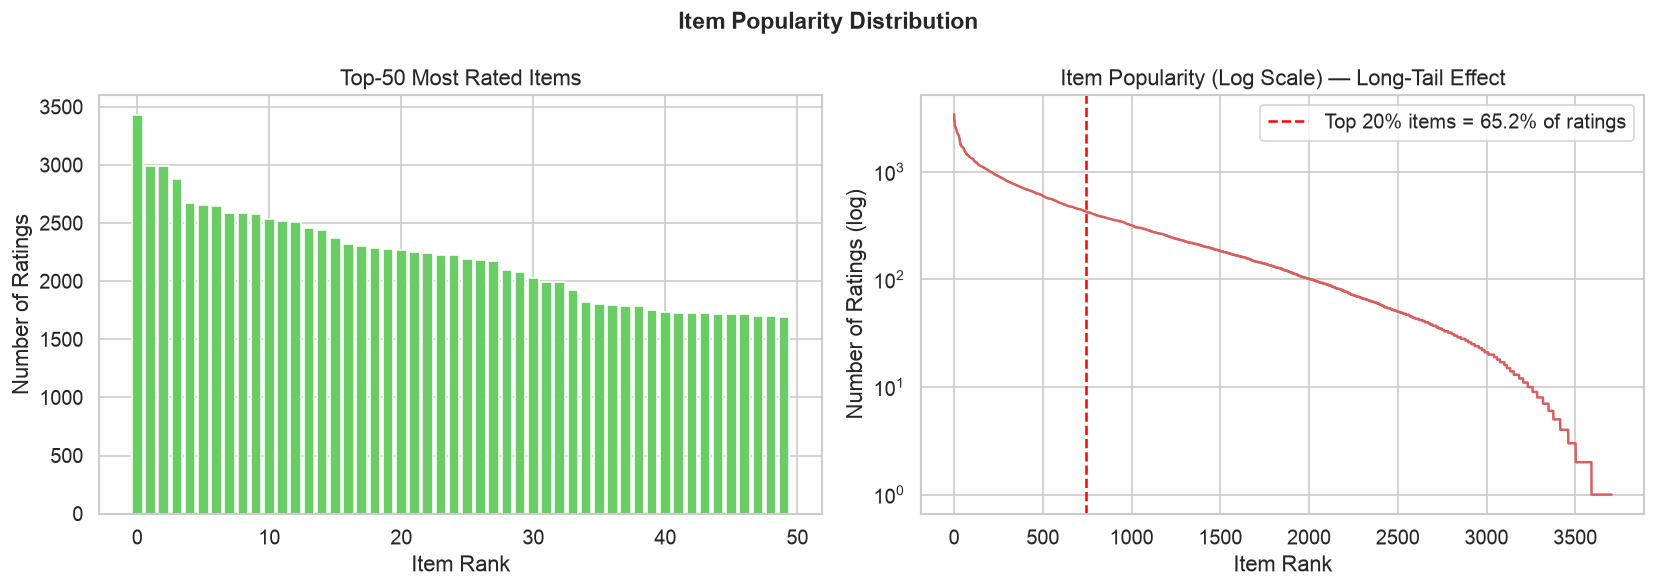

Top 20% items cover 65.2% of all ratings — strong long-tail effect.


In [43]:
item_counts = ratings.groupby('item_idx')['user_idx'].count().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Top 50 items
axes[0].bar(range(50), item_counts.values[:50], color=sns.color_palette('muted')[2])
axes[0].set_title('Top-50 Most Rated Items')
axes[0].set_xlabel('Item Rank')
axes[0].set_ylabel('Number of Ratings')

# Full long-tail
axes[1].plot(range(len(item_counts)), item_counts.values, color=sns.color_palette('muted')[3])
axes[1].set_yscale('log')
axes[1].set_title('Item Popularity (Log Scale) — Long-Tail Effect')
axes[1].set_xlabel('Item Rank')
axes[1].set_ylabel('Number of Ratings (log)')

# Annotate: top 20% items cover X% of ratings
top20_items = int(len(item_counts) * 0.2)
top20_ratings = item_counts.values[:top20_items].sum()
pct = top20_ratings / len(ratings) * 100
axes[1].axvline(top20_items, color='red', linestyle='--', label=f'Top 20% items = {pct:.1f}% of ratings')
axes[1].legend()

plt.suptitle('Item Popularity Distribution', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/intermediate_report/fig_item_popularity.png', bbox_inches='tight')
plt.show()

print(f'Top 20% items cover {pct:.1f}% of all ratings — strong long-tail effect.')

## 4. Interaction Matrix Sparsity

In [44]:
n_users = loader.n_users
n_items = loader.n_items
n_interactions = len(ratings)
sparsity = 1 - n_interactions / (n_users * n_items)

print(f'Users       : {n_users:,}')
print(f'Items       : {n_items:,}')
print(f'Ratings     : {n_interactions:,}')
print(f'Matrix size : {n_users:,} × {n_items:,} = {n_users * n_items:,}')
print(f'Sparsity    : {sparsity:.4%}')
print(f'Density     : {1-sparsity:.4%}')

Users       : 6,040
Items       : 3,706
Ratings     : 1,000,209
Matrix size : 6,040 × 3,706 = 22,384,240
Sparsity    : 95.5316%
Density     : 4.4684%


## 5. Genre Distribution

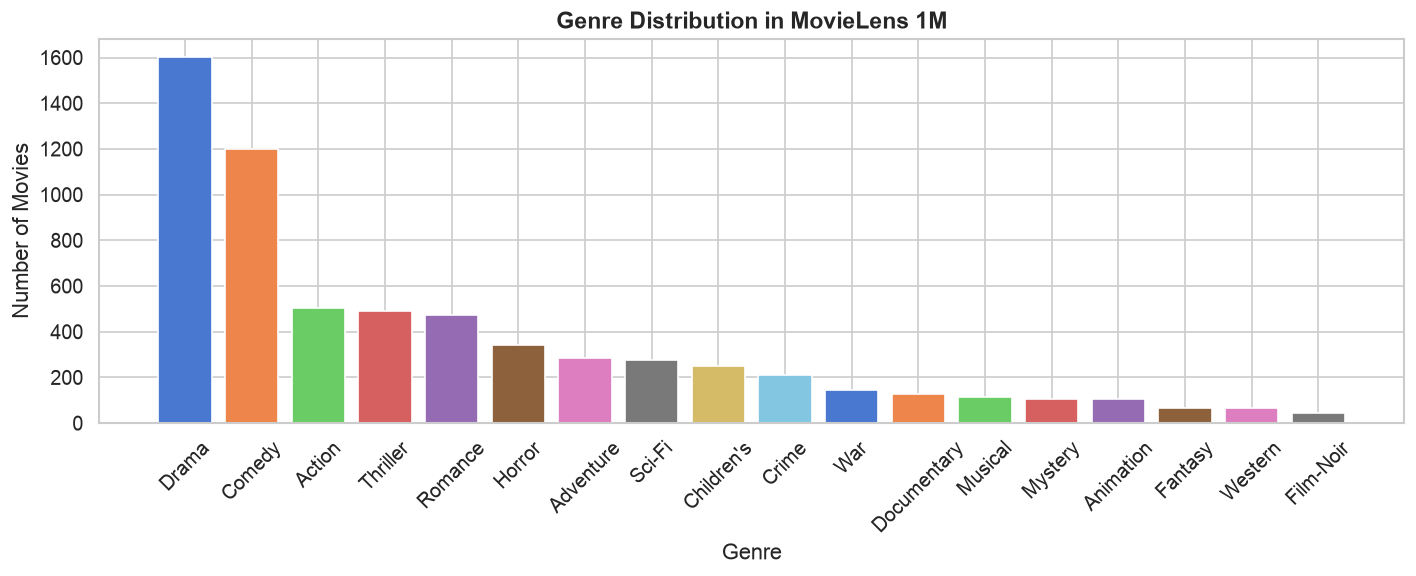

Top 5 genres:
Drama       1603
Comedy      1200
Action       503
Thriller     492
Romance      471
Name: count, dtype: int64


In [45]:
all_genres = [g for genre_list in movies['genre_list'] for g in genre_list]
genre_counts = pd.Series(all_genres).value_counts()

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(genre_counts.index, genre_counts.values, color=sns.color_palette('muted', len(genre_counts)))
ax.set_title('Genre Distribution in MovieLens 1M', fontsize=14, fontweight='bold')
ax.set_xlabel('Genre')
ax.set_ylabel('Number of Movies')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('../reports/intermediate_report/fig_genre_dist.png', bbox_inches='tight')
plt.show()

print('Top 5 genres:')
print(genre_counts.head())

## 6. Temporal Analysis

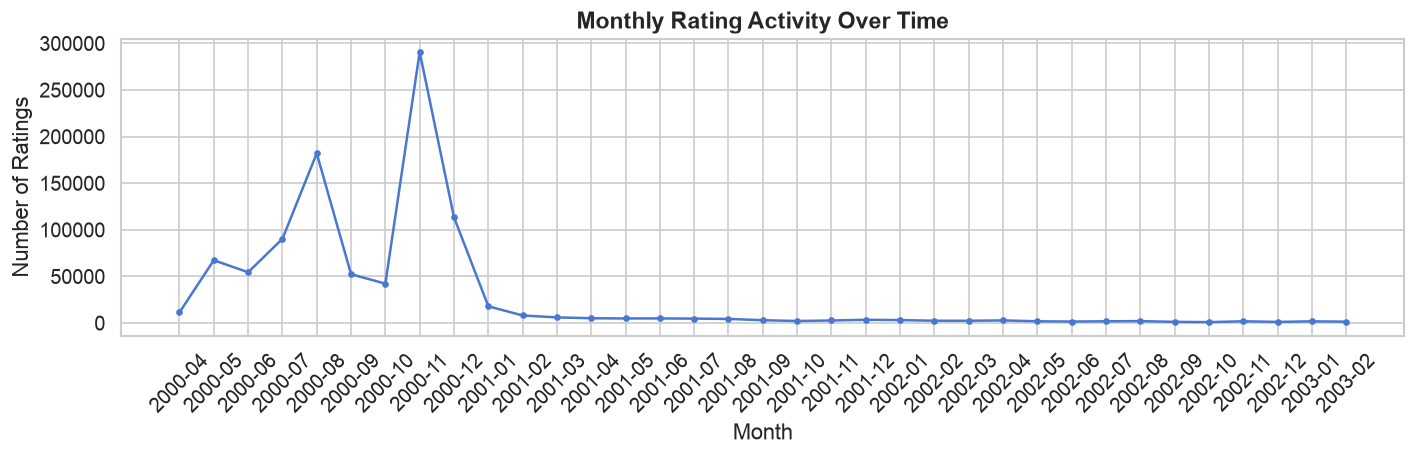

Date range: 2000-04-25 → 2003-02-28


In [46]:
ratings['datetime'] = pd.to_datetime(ratings['timestamp'], unit='s')
ratings['month'] = ratings['datetime'].dt.to_period('M')

monthly = ratings.groupby('month').size()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot([str(m) for m in monthly.index], monthly.values, marker='o', markersize=3,
        color=sns.color_palette('muted')[0])
ax.set_title('Monthly Rating Activity Over Time', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Number of Ratings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../reports/intermediate_report/fig_temporal.png', bbox_inches='tight')
plt.show()

print(f'Date range: {ratings["datetime"].min().date()} → {ratings["datetime"].max().date()}')

## 7. Train / Val / Test Split Statistics

In [47]:
train_df, val_df, test_df = loader.temporal_split()
print(f'Train : {len(train_df):>8,} ({len(train_df)/len(ratings)*100:.1f}%)')
print(f'Val   : {len(val_df):>8,} ({len(val_df)/len(ratings)*100:.1f}%)')
print(f'Test  : {len(test_df):>8,} ({len(test_df)/len(ratings)*100:.1f}%)')
print(f'Total : {len(ratings):>8,}')

Train :  805,443 (80.5%)
Val   :   97,383 (9.7%)
Test  :   97,383 (9.7%)
Total : 1,000,209


## Summary

| Observation | Value | Implication |
|---|---|---|
| Sparsity | ~95.5% | Collaborative filtering is challenging — funnel approach reduces the item space |
| Long-tail effect | Top 20% items → ~80% ratings | Popularity bias must be addressed in evaluation |
| Dominant genre | Drama | Genre-based CBF can complement SVD for niche items |
| Median ratings/user | ~96 | Enough history for most users; some cold-start risk |

→ Continue to `02_stage1_svd.ipynb`